# 02 - ERP and P300 Analysis

Goal: extract and quantify the auditory P300 response for standard and oddball stimuli.

In [1]:
from pathlib import Path
import mne
import matplotlib.pyplot as plt

In [3]:
DATA_ROOT = Path(
    r"C:\Users\Fafou\Desktop\Postdoc_UBC\code\EEG_project"
    r"\project1_openneuro\data\ds003061"
)

eeg_file = DATA_ROOT / "sub-001" / "eeg" / "sub-001_task-P300_run-1_eeg.set"

raw = mne.io.read_raw_eeglab(
    eeg_file,
    preload=True
)

print(raw)

C:\Users\Fafou\AppData\Local\Temp\ipykernel_35452\2590537075.py:8: RuntimeWarning: Unknown types found, setting as type EEG:
temp: ['Temp']
  raw = mne.io.read_raw_eeglab(


<RawEEGLAB | sub-001_task-P300_run-1_eeg.set, 79 x 194048 (758.0 s), ~117.0 MiB, data loaded>


C:\Users\Fafou\AppData\Local\Temp\ipykernel_35452\2590537075.py:8: RuntimeWarning: Not setting positions of 14 gsr/misc/resp channels found in montage:
['EXG1', 'EXG2', 'EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8', 'GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(


In [4]:
raw_clean = raw.copy()

In [5]:
raw_clean.set_eeg_reference("average")

raw_clean.filter(
    l_freq=1.0,
    h_freq=None
)

EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.
Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 1 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Filter length: 845 samples (3.301 s)



<RawEEGLAB | sub-001_task-P300_run-1_eeg.set, 79 x 194048 (758.0 s), ~117.0 MiB, data loaded>

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


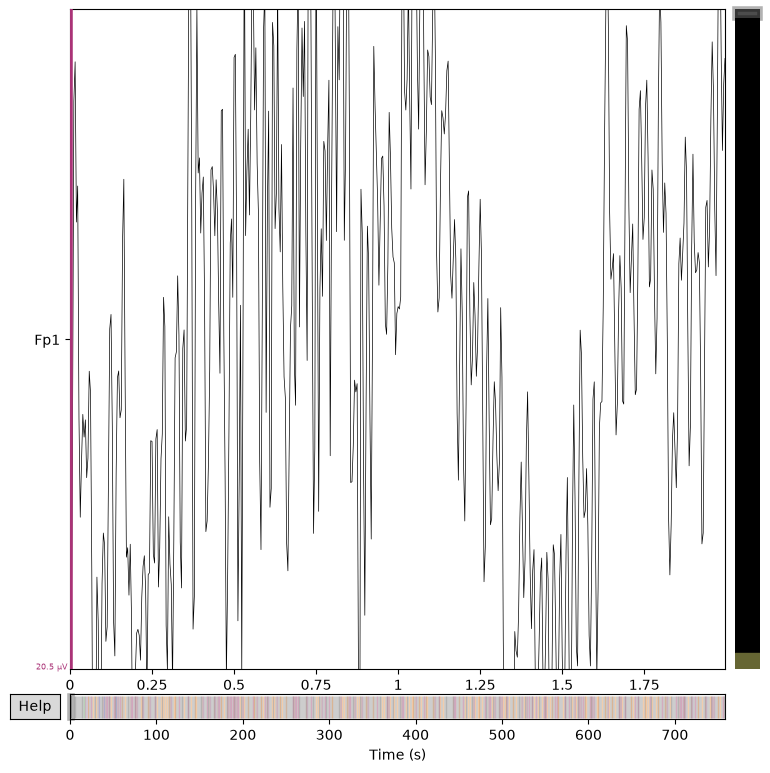

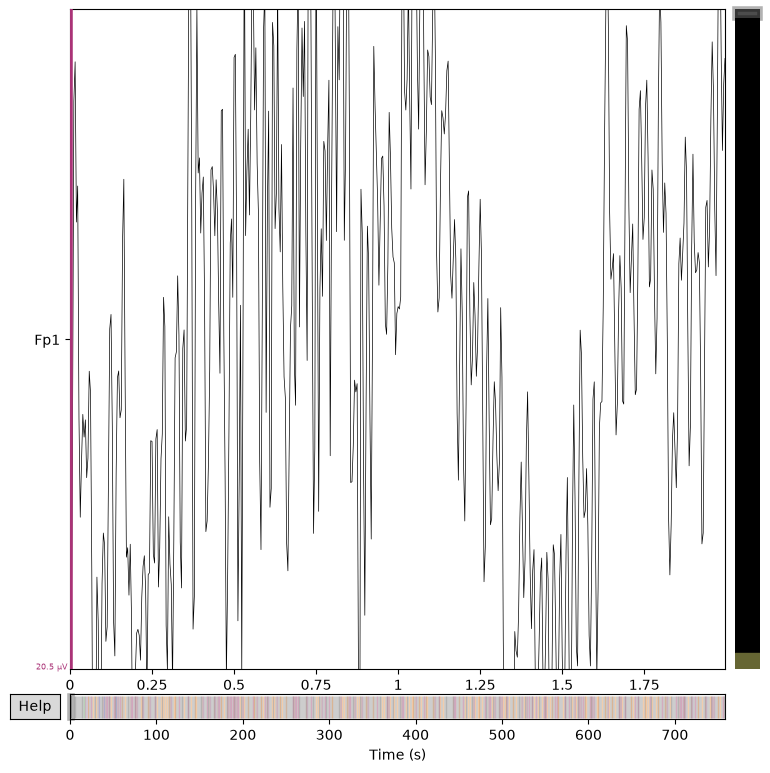

In [13]:
raw_clean.plot(
    duration=2,
    n_channels=1,
    scalings="auto"
)

In [27]:
picks = ["Fp1", "Fz", "Cz", "Pz", "Oz"]

start = 0
duration = 1

data, times = raw_clean[picks, int(start * raw_clean.info["sfreq"]):
                              int((start + duration) * raw_clean.info["sfreq"])]

data = data * 1e6

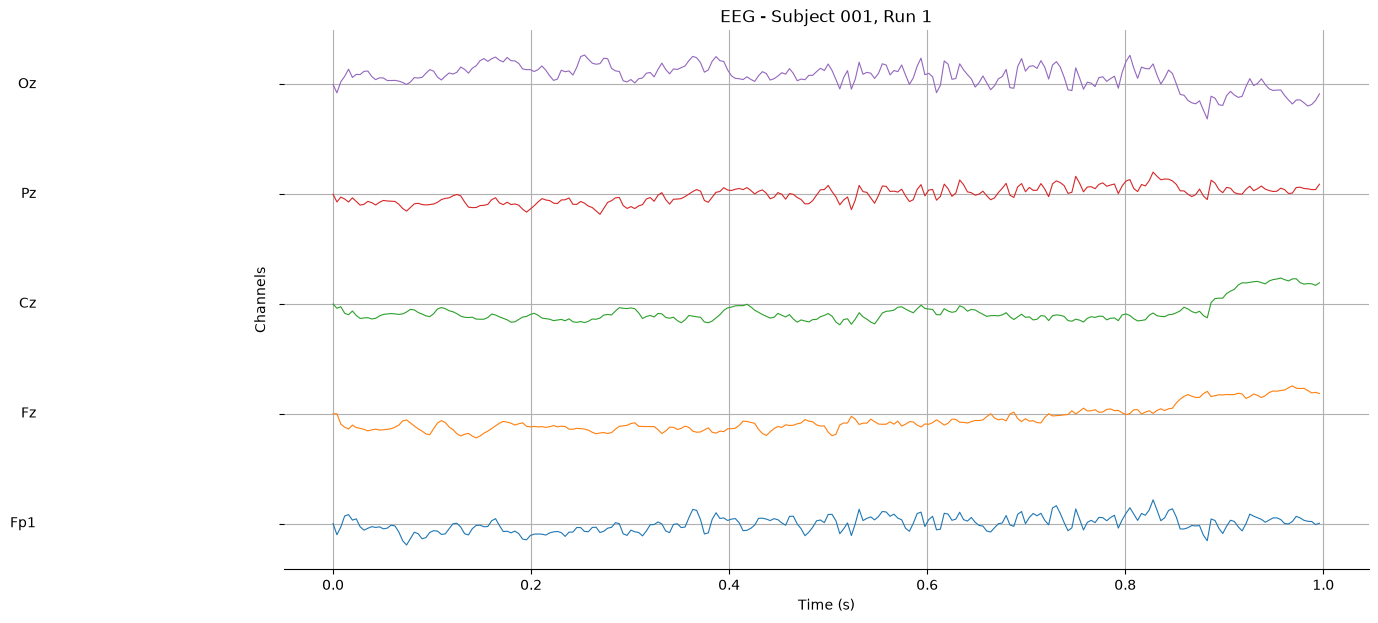

In [28]:
fig, ax = plt.subplots(figsize=(14, 7))

offset = 100

for i, channel in enumerate(picks):
    ax.plot(times, data[i] + i * offset, linewidth=0.8)
    ax.text(times[0] - 0.3, i * offset, channel, ha="right", va="center")

ax.set_xlabel("Time (s)")
ax.set_ylabel("Channels")
ax.set_title("EEG - Subject 001, Run 1")
ax.set_yticks([])
ax.spines[["top", "right", "left"]].set_visible(False)
ax.set_yticks([i * offset for i in range(len(picks))])
ax.set_yticklabels([])
ax.grid(visible=True, axis="y")
ax.grid(visible=True)

plt.show()

In [29]:
events, event_id = mne.events_from_annotations(raw_clean)

print(event_id)

Used Annotations descriptions: ['ignore', 'noise', 'noise_with_reponse', 'oddball', 'oddball_with_reponse', 'response', 'standard']
{'ignore': 1, 'noise': 2, 'noise_with_reponse': 3, 'oddball': 4, 'oddball_with_reponse': 5, 'response': 6, 'standard': 7}


In [32]:
epochs = mne.Epochs(
    raw_clean,
    events,
    event_id={
        "standard": event_id["standard"],
        "oddball/no_response": event_id["oddball"],
        "oddball/response": event_id["oddball_with_reponse"],
    },
    tmin=-0.2,
    tmax=0.8,
    baseline=(-0.2, 0),
    preload=True
)

print("Standard:", len(epochs["standard"]))
print("Oddball:", len(epochs["oddball"]))

Not setting metadata
635 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 635 events and 257 original time points ...
1 bad epochs dropped
Standard: 521
Oddball: 113


Used Annotations descriptions: ['ignore', 'noise', 'noise_with_reponse', 'oddball', 'oddball_with_reponse', 'response', 'standard']
Event IDs:
{'ignore': 1, 'noise': 2, 'noise_with_reponse': 3, 'oddball': 4, 'oddball_with_reponse': 5, 'response': 6, 'standard': 7}
Not setting metadata
635 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 635 events and 257 original time points ...
1 bad epochs dropped
Standard epochs: 521
Oddball epochs: 113


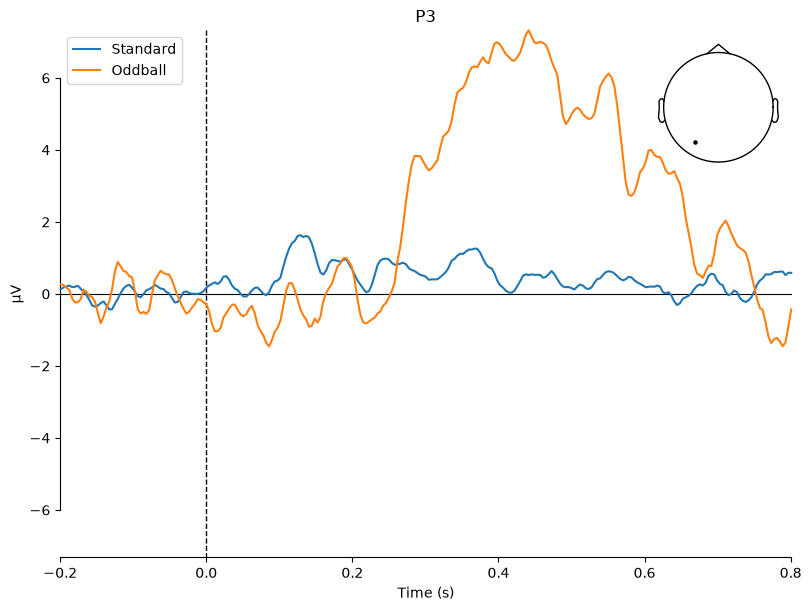

[<Figure size 800x600 with 2 Axes>]

In [37]:
# Convert annotations such as "standard" and "oddball"
# into numerical event markers that MNE can use.
events, event_id = mne.events_from_annotations(raw_clean)

print("Event IDs:")
print(event_id)


# Cut the continuous EEG into epochs around standard and oddball stimuli.
epochs = mne.Epochs(
    raw_clean,
    events,
    event_id={
        "standard": event_id["standard"],
        "oddball/no_response": event_id["oddball"],
        "oddball/response": event_id["oddball_with_reponse"],
    },
    tmin=-0.2,              # Start 200 ms before stimulus
    tmax=0.8,               # End 800 ms after stimulus
    baseline=(-0.2, 0),     # Baseline-correct using pre-stimulus period
    preload=True            # Load epochs into memory
)


# Check how many trials we have for each condition.
print("Standard epochs:", len(epochs["standard"]))
print("Oddball epochs:", len(epochs["oddball"]))


# Average individual trials to obtain ERPs.
standard_erp = epochs["standard"].average()
oddball_erp = epochs["oddball"].average()


# Compare standard and oddball ERPs at electrode Pz.
mne.viz.plot_compare_evokeds(
    {
        "Standard": standard_erp,
        "Oddball": oddball_erp
    },
    picks="P3",
    show_sensors=True
)